# Lab 5: “Shout STOP!” — TinyML Keyword Spotting
**Aim:** Train a DS-CNN keyword spotter for `stop`, then export an INT8 TensorFlow Lite model.

**Dataset note:** the linked *Mini Speech Commands* dataset has `yes/no/up/down/left/right/on/off`; it has no `stop` or `go` folder. This notebook therefore uses the larger official Speech Commands v0.02 dataset so the STOP-specific lab can actually run. The download is large and may take several minutes.

## 1. Setup

In [1]:
!pip -q install librosa soundfile scikit-learn seaborn
import os, glob, random, json, pathlib, tarfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display, tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, classification_report
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
SR=16000; N=16000; N_MFCC=10
CLASSES=["stop","_unknown_","_silence_"]
label_id={c:i for i,c in enumerate(CLASSES)}
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Download dataset and create balanced classes

In [2]:
ROOT="/content/speech_commands"; ARCHIVE="/content/speech_commands_v0.02.tar.gz"
os.makedirs(ROOT, exist_ok=True)
URL="http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
if not os.path.exists(f"{ROOT}/stop"):
    if not os.path.exists(ARCHIVE): urllib.request.urlretrieve(URL, ARCHIVE)
    with tarfile.open(ARCHIVE,"r:gz") as t: t.extractall(ROOT)
stop=glob.glob(f"{ROOT}/stop/*.wav")
noise=glob.glob(f"{ROOT}/_background_noise_/*.wav")
all_wavs=glob.glob(f"{ROOT}/*/*.wav")
unknown=[p for p in all_wavs if os.path.basename(os.path.dirname(p)) not in
         ["stop","_background_noise_"] and not os.path.basename(os.path.dirname(p)).startswith("_")]
random.shuffle(unknown); unknown=unknown[:len(stop)]
assert stop and noise, "Dataset download incomplete."
def speaker(p): return pathlib.Path(p).stem.split("_nohash_")[0]
rows=[{"path":p,"label":"stop","group":speaker(p)} for p in stop]
rows += [{"path":p,"label":"_unknown_","group":speaker(p)} for p in unknown]
# One background-noise segment per STOP example; unique group avoids split leakage.
rows += [{"path":random.choice(noise),"label":"_silence_","group":f"noise_{i}"} for i in range(len(stop))]
df=pd.DataFrame(rows).sample(frac=1,random_state=SEED).reset_index(drop=True)
display(df.label.value_counts().rename("examples").to_frame())

/tmp/ipykernel_502/601901742.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(ARCHIVE,"r:gz") as t: t.extractall(ROOT)


,examples
label,
_unknown_,3872
_silence_,3872
stop,3872


## 3. Speaker-wise 80/10/10 split

In [3]:
s1=GroupShuffleSplit(n_splits=1,test_size=.10,random_state=SEED)
tv,te=next(s1.split(df,groups=df.group))
trainval,test=df.iloc[tv].reset_index(drop=True),df.iloc[te].reset_index(drop=True)
s2=GroupShuffleSplit(n_splits=1,test_size=1/9,random_state=SEED)
tr,va=next(s2.split(trainval,groups=trainval.group))
train,val=trainval.iloc[tr].reset_index(drop=True),trainval.iloc[va].reset_index(drop=True)
table=pd.DataFrame({"train":train.label.value_counts(),"validation":val.label.value_counts(),
                    "test":test.label.value_counts()}).fillna(0).astype(int).reindex(CLASSES)
display(table)

,train,validation,test
label,,,
stop,3078,374,420
_unknown_,3119,383,370
_silence_,3091,387,394


## 4. Preprocessing and MFCC features
Audio is mono, resampled to 16 kHz, clipped/padded to 1 second. Frames use a 30 ms window (480 samples) and 20 ms hop (320 samples).

In [4]:
def audio(path, silence=False, augment=False):
    y,_=librosa.load(path,sr=SR,mono=True)
    if silence:
        if len(y)<N: y=np.tile(y,int(np.ceil(N/len(y))))
        start=random.randint(0,len(y)-N); y=y[start:start+N]
        y=.08*y/(np.max(np.abs(y))+1e-8)
    elif len(y)>N:
        start=random.randint(0,len(y)-N) if augment else 0; y=y[start:start+N]
    else: y=np.pad(y,(0,N-len(y)))
    y=np.clip(y,-1,1).astype(np.float32)
    if augment and not silence:
        y=np.roll(y,random.randint(-1600,1600))
    if augment and silence: y += np.random.normal(0,.002,N).astype(np.float32)
    return y

def mfcc(y):
    z=librosa.feature.mfcc(y=y,sr=SR,n_mfcc=N_MFCC,n_fft=480,
                           win_length=480,hop_length=320)
    z=z[:,:49]
    if z.shape[1]<49: z=np.pad(z,((0,0),(0,49-z.shape[1])))
    return z.T.astype(np.float32)  # (49, 10)

def make_xy(frame, augment=False):
    X=[]; y=[]
    for r in frame.itertuples():
        a=audio(r.path,silence=r.label=="_silence_",augment=augment)
        X.append(mfcc(a)); y.append(label_id[r.label])
    return np.array(X)[...,None],np.array(y,dtype=np.int32)
Xtr,ytr=make_xy(train,True); Xv,yv=make_xy(val); Xte,yte=make_xy(test)
print("Input tensor:",Xtr.shape)

Input tensor: (9288, 49, 10, 1)


## 5. Visualise STOP and GO
**Why MFCCs differ:** (1) Stop and go contain different phonemes and resonant frequency patterns. (2) MFCCs summarize the short-time spectral envelope over time. (3) The DS-CNN learns these patterns, although accents and noise can still cause mistakes.

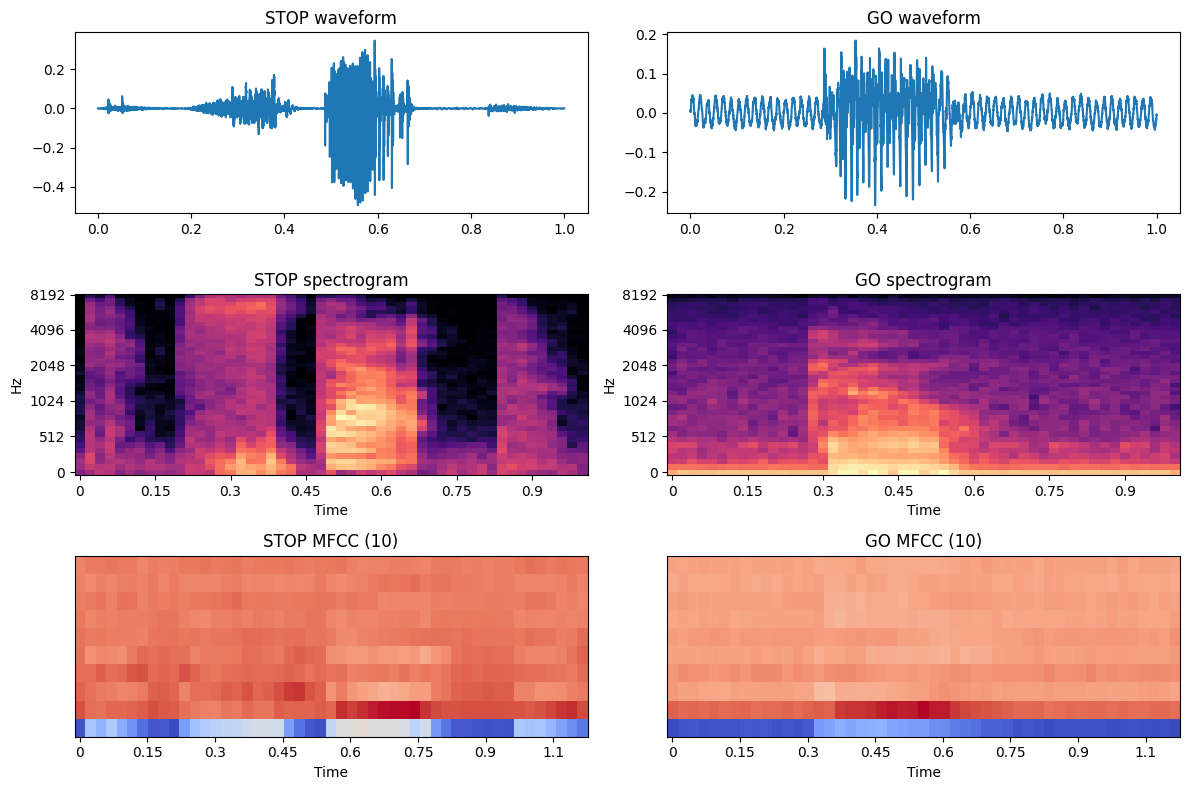

In [5]:
go=glob.glob(f"{ROOT}/go/*.wav")
assert go, "Expected a 'go' folder in Speech Commands v0.02."
fig,ax=plt.subplots(3,2,figsize=(12,8))
for j,(name,path) in enumerate([("STOP",random.choice(stop)),("GO",random.choice(go))]):
    y=audio(path)
    mel=librosa.feature.melspectrogram(y=y,sr=SR,n_fft=480,hop_length=320,n_mels=40)
    z=librosa.feature.mfcc(y=y,sr=SR,n_mfcc=10,n_fft=480,win_length=480,hop_length=320)[:,:49]
    ax[0,j].plot(np.arange(len(y))/SR,y); ax[0,j].set_title(name+" waveform")
    librosa.display.specshow(librosa.power_to_db(mel,ref=np.max),sr=SR,hop_length=320,
                             x_axis="time",y_axis="mel",ax=ax[1,j]); ax[1,j].set_title(name+" spectrogram")
    librosa.display.specshow(z,x_axis="time",ax=ax[2,j]); ax[2,j].set_title(name+" MFCC (10)")
plt.tight_layout(); plt.show()

## 6. Build a compact DS-CNN

In [6]:
def build_model():
    i=tf.keras.Input((49,10,1)); x=tf.keras.layers.Normalization()(i)
    x=tf.keras.layers.Conv2D(24,3,strides=(2,1),padding="same",use_bias=False)(x)
    x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.ReLU()(x)
    for f in (32,48,64):
        x=tf.keras.layers.DepthwiseConv2D(3,padding="same",use_bias=False)(x)
        x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.ReLU()(x)
        x=tf.keras.layers.Conv2D(f,1,padding="same",use_bias=False)(x)
        x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.ReLU()(x)
        x=tf.keras.layers.MaxPool2D((2,1))(x)
    x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dropout(.25)(x)
    o=tf.keras.layers.Dense(3,activation="softmax")(x)
    m=tf.keras.Model(i,o); m.compile("adam","sparse_categorical_crossentropy",metrics=["accuracy"])
    return m
model=build_model(); model.layers[1].adapt(Xtr); model.summary()
print("Parameters:",model.count_params())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 49, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 49, 10, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 25, 10, 24)     │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 10, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 25, 10, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 25, 10, 24)     │           216 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 10, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 25, 10, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 25, 10, 32)     │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 25, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 12, 10, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 12, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 10, 48)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 10, 48)     │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 12, 10, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 10, 48)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 6, 10, 48)      │           432 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 6, 10, 48)      │           19

 Total params: 7,814 (30.53 KB)

 Trainable params: 7,267 (28.39 KB)

 Non-trainable params: 547 (2.14 KB)

Parameters: 7814


## 7. Train with time-shift and background-noise augmentation; plot curves

Epoch 1/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 35s 117ms/step - accuracy: 0.8339 - loss: 0.4313 - val_accuracy: 0.3383 - val_loss: 1.2490 - learning_rate: 0.0010
Epoch 2/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9562 - loss: 0.1382 - val_accuracy: 0.3383 - val_loss: 2.2679 - learning_rate: 0.0010
Epoch 3/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9690 - loss: 0.0961 - val_accuracy: 0.3462 - val_loss: 1.7593 - learning_rate: 0.0010
Epoch 4/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9738 - loss: 0.0794 - val_accuracy: 0.9248 - val_loss: 0.2251 - learning_rate: 5.0000e-04
Epoch 5/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9767 - loss: 0.0705 - val_accuracy: 0.9650 - val_loss: 0.0949 - learning_rate: 5.0000e-04
Epoch 6/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9785 - loss: 0.0653 - val_accuracy: 0.9677 - val_loss: 0.0880 - learning_rate: 5.0000e-04
Epoch 7/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9788 - 

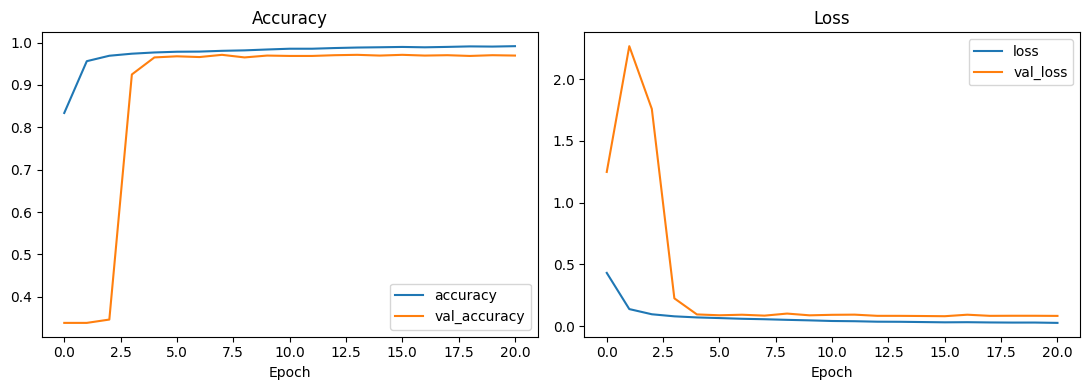

In [7]:
hist=model.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=25,batch_size=64,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5,restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(patience=2,factor=.5)],verbose=1)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for key in ["accuracy","val_accuracy"]: ax[0].plot(hist.history[key],label=key)
for key in ["loss","val_loss"]: ax[1].plot(hist.history[key],label=key)
ax[0].set_title("Accuracy"); ax[1].set_title("Loss")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

## 8. Test accuracy, confusion matrix, misses and false alarms

              precision    recall  f1-score   support

        stop       0.98      0.95      0.96       420
   _unknown_       0.94      0.98      0.96       370
   _silence_       1.00      0.99      0.99       394

    accuracy                           0.97      1184
   macro avg       0.97      0.97      0.97      1184
weighted avg       0.97      0.97      0.97      1184



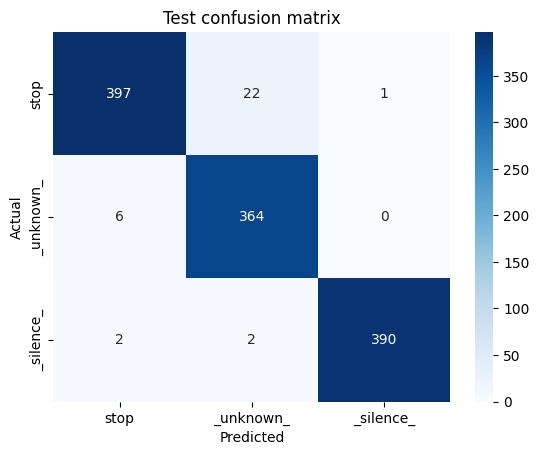

Test accuracy: 97.213%
STOP misses: 23  | non-STOP false alarms: 8


In [8]:
prob=model.predict(Xte,verbose=0); pred=prob.argmax(1)
cm=confusion_matrix(yte,pred,labels=[0,1,2])
print(classification_report(yte,pred,target_names=CLASSES,zero_division=0))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=CLASSES,yticklabels=CLASSES,cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Test confusion matrix"); plt.show()
miss=int(np.sum((yte==0)&(pred!=0)))
false_alarm=int(np.sum((yte!=0)&(pred==0)))
print(f"Test accuracy: {np.mean(pred==yte):.3%}")
print("STOP misses:",miss," | non-STOP false alarms:",false_alarm)

## 9. Convert to Float32 and full INT8 TFLite

In [9]:
conv=tf.lite.TFLiteConverter.from_keras_model(model)
blob_float=conv.convert()
def representative():
    for i in np.random.choice(len(Xtr),min(300,len(Xtr)),replace=False):
        yield [Xtr[i:i+1].astype(np.float32)]
conv=tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations=[tf.lite.Optimize.DEFAULT]; conv.representative_dataset=representative
conv.target_spec.supported_ops=[tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type=tf.int8; conv.inference_output_type=tf.int8
blob_int8=conv.convert()
open("/content/kws_float.tflite","wb").write(blob_float)
open("/content/kws_int8.tflite","wb").write(blob_int8)

def lite_predict(blob,X):
    it=tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
    ii=it.get_input_details()[0]; oo=it.get_output_details()[0]; ans=[]
    for x in X:
        if ii["dtype"]==np.int8:
            s,z=ii["quantization"]; q=np.clip(np.round(x[None]/s+z),-128,127).astype(np.int8)
        else: q=x[None].astype(np.float32)
        it.set_tensor(ii["index"],q); it.invoke(); v=it.get_tensor(oo["index"])[0]
        if oo["dtype"]==np.int8:
            s,z=oo["quantization"]; v=(v.astype(float)-z)*s
        ans.append(v.argmax())
    return np.array(ans)
pf=lite_predict(blob_float,Xte); pi=lite_predict(blob_int8,Xte)
results=pd.DataFrame([
 {"model":"Keras float32","size_KB":model.count_params()*4/1024,"accuracy":np.mean(pred==yte)},
 {"model":"TFLite float32","size_KB":len(blob_float)/1024,"accuracy":np.mean(pf==yte)},
 {"model":"TFLite int8","size_KB":len(blob_int8)/1024,"accuracy":np.mean(pi==yte)}])
display(results.round(4))
print("INT8 under 100 KB:",len(blob_int8)<100*1024)

Saved artifact at '/tmp/tmpsxckae8p'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 10, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135376170343632: TensorSpec(shape=(1, 1, 1, 1), dtype=tf.float32, name=None)
  135376170343440: TensorSpec(shape=(1, 1, 1, 1), dtype=tf.float32, name=None)
  135376171257104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171254992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171256720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171254800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171256912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171255376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171268240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135376171268048: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,model,size_KB,accuracy
0,Keras float32,30.5234,0.9721
1,TFLite float32,35.5508,0.9721
2,TFLite int8,23.2656,0.9721


INT8 under 100 KB: True


## 10. Export Lab 6 files

In [10]:
config={"sample_rate":SR,"duration_seconds":1,"n_mfcc":10,"n_fft":480,
 "win_length":480,"hop_length":320,"mfcc_frames":49,"input_shape":[49,10,1],
 "labels":CLASSES,"input_dtype":"int8","output_dtype":"int8","model_file":"kws_int8.tflite"}
with open("/content/kws_config.json","w") as f: json.dump(config,f,indent=2)
print("Created /content/kws_int8.tflite and /content/kws_config.json")

Created /content/kws_int8.tflite and /content/kws_config.json


## 11. Upload a WAV file and run offline inference

In [ ]:
from google.colab import files
uploaded=files.upload()
def predict_wav(path,model_path="/content/kws_int8.tflite"):
    y=audio(path); x=mfcc(y)[None,...,None]
    it=tf.lite.Interpreter(model_path=model_path); it.allocate_tensors()
    ii=it.get_input_details()[0]; oo=it.get_output_details()[0]
    s,z=ii["quantization"]; q=np.clip(np.round(x/s+z),-128,127).astype(np.int8)
    it.set_tensor(ii["index"],q); it.invoke()
    raw=it.get_tensor(oo["index"])[0]; s,z=oo["quantization"]
    scores=(raw.astype(float)-z)*s; idx=int(scores.argmax())
    return CLASSES[idx],float(scores[idx]),dict(zip(CLASSES,scores.tolist()))
for name in uploaded:
    label,score,scores=predict_wav(name)
    print(name,"=>",label,"score",round(score,3),{k:round(v,3) for k,v in scores.items()})

## 12. Live Voice Recording and Conveyor Belt Simulation
Run the cell below to record a 1-second audio clip from your microphone. The model will classify the keyword and dynamically update a visual signal mimicking a conveyor belt's safety status (Green = Running, Red = STOP!).

In [ ]:
import html
from IPython.display import display, Javascript, HTML
from google.colab import output

# JavaScript to record 1 second of audio from the user's microphone
RECORD_JS = """
const sleep  = time => new Promise(resolve => setTimeout(resolve, time));
const b2text = blob => new Promise(resolve => {
  const reader = new FileReader();
  reader.onloadend = e => resolve(e.srcElement.result);
  reader.readAsDataURL(blob);
});
var record = html_element => new Promise(async resolve => {
  const stream = await navigator.mediaDevices.getUserMedia({ audio: true });
  const activeStream = stream;
  const recorder = new MediaRecorder(stream);
  let chunks = [];
  recorder.ondataavailable = e => chunks.push(e.data);
  recorder.start();
  await sleep(1000); // Record exactly 1 second
  recorder.stop();
  recorder.onstop = async () => {
    activeStream.getTracks().forEach(track => track.stop());
    const blob = new Blob(chunks, { type: 'audio/wav' });
    const text = await b2text(blob);
    resolve(text);
  };
});
"""

def record_audio_clip():
    display(HTML("<p style='color: #007bff; font-weight: bold;'>🎙️ Recording... Speak now (1 second) </p>"))
    display(Javascript(RECORD_JS))
    audio_data = output.eval_js('record()')
    import base64
    # Decode the base64 URI back to bytes
    header, encoded = audio_data.split(",", 1)
    data = base64.b64decode(encoded)
    # Write to a temporary WAV file
    temp_path = "/content/live_temp.wav"
    with open(temp_path, "wb") as f:
        f.write(data)
    return temp_path


In [ ]:
def run_live_simulation():
    # 1. Record the live audio
    wav_path = record_audio_clip()

    # 2. Run inference using our predict_wav logic
    label, score, scores = predict_wav(wav_path)

    # 3. Create visual feedback for the Conveyor Belt
    if label == "stop":
        status_color = "#dc3545"
        status_text = "🔴 CONVEYOR BELT STOPPED!"
        animation_style = "border-color: #dc3545; background-color: #f8d7da;"
        action_message = "<h2 style='color: #721c24; margin:0;'>⚠️ EMERGENCY STOP TRIGGERED ⚠️</h2>"
    else:
        status_color = "#28a745"
        status_text = f"🟢 CONVEYOR RUNNING ({label})"
        animation_style = "border-color: #28a745; background-color: #d4edda;"
        action_message = "<h2 style='color: #155724; margin:0;'>⚡ Conveyor Belt Operating Normally ⚡</h2>"

    # Beautiful dashboard visualization
    html_code = f"""
    <div style='font-family: Arial, sans-serif; max-width: 500px; padding: 20px; border-radius: 10px; border: 3px solid; margin: 10px 0; {animation_style}'>
        <div style='display: flex; justify-content: space-between; align-items: center; margin-bottom: 15px;'>
            <span style='font-size: 1.5em; font-weight: bold; color: {status_color};'>{status_text}</span>
            <span style='font-size: 1em; font-weight: bold; color: #555;'>Conf: {score:.1%}</span>
        </div>
        <div style='text-align: center; padding: 15px; border-radius: 5px; background: white; box-shadow: inset 0 0 10px rgba(0,0,0,0.1); margin-bottom: 15px;'>
            {action_message}
        </div>
        <div style='font-size: 0.9em; color: #555;'>
            <strong>Detailed Scores:</strong><br>
            Stop: {scores.get('stop', 0.0):.3f} |
            Unknown: {scores.get('_unknown_', 0.0):.3f} |
            Silence: {scores.get('_silence_', 0.0):.3f}
        </div>
    </div>
    """
    display(HTML(html_code))

# Run the system simulation
run_live_simulation()

## Safety and viva notes
- **Miss:** an actual STOP clip predicted as another class; this is the dangerous error.
- **False alarm:** a non-STOP clip predicted as STOP; this unnecessarily halts production.
- Check measured model size and test accuracy rather than assuming the target values are achieved.
- WAV upload inference is offline. A real-time mic needs rolling audio windows and threshold/debounce logic.
- This experiment is a proof of concept, **not a certified emergency-stop system**. Any deployed system needs fail-safe hardware, extensive real-factory testing and safety engineering.